# Deep Hedging — comparaison de stratégies de couverture

**Projet de Deep Learning, M2 ISF — version révisée**  
**Question :** *L'apprentissage d'une stratégie de couverture par réseau dense apporte-t-il un avantage par rapport à Black-Scholes lorsque des coûts de transaction sont présents ?*

L'objectif est **de comprendre une méthode, de la reproduire à petite échelle puis de la tester**, sans multiplier les architectures ou les techniques qui dépassent le cours. Cette étude s'inspire de l'article de Brugière et Turinici (2025) ; il ne s'agit **pas d'une reproduction exhaustive** de toutes ses expériences.

| Partie | Objectif | Répartition |
|---|---|---|
| 1 | Modèle financier, réseau, apprentissage et validation | Étudiant 1 |
| 2 | Sensibilité aux frais et décisions de couverture | Étudiant 2 |
| 3 | Application à des trajectoires historiques observées | Étudiant 3 |

Un **call européen hypothétique** est vendu, et sa livraison physique est couverte à dates discrètes. Les chiffres représentent des **coûts de couverture normalisés**, pas des rendements d'investissement. **Convention conservée du travail initial** : pas de frais sur la position d'ouverture ; frais sur les rééquilibrages et sur l'ajustement final. Cette hypothèse sera discutée en conclusion.

## 1 — Hypothèses financières et données simulées

Sous la probabilité historique, le prix suit un mouvement brownien géométrique :

$$\frac{dS_t}{S_t}=\mu\,dt+\sigma\,dW_t.$$

Pour rester proche du notebook initial, on prend $S_0=K=1$, $\mu=5\%$, $\sigma=20\%$, $r=0$, $T=0{,}25$ année et **30 rééquilibrages**. Les simulations sont *nouvelles à chaque exécution*, mais reproductibles par leur graine.

On sépare **train / validation / test** : le test n'est **jamais** utilisé pour sélectionner une époque ou modifier les hyperparamètres.

In [3]:
from pathlib import Path
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from scipy.stats import norm
from IPython.display import display

# Un CPU et des résultats reproductibles suffisent pour ce petit projet.
torch.set_num_threads(1)
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

S0, K, MU, SIGMA, R, T = 1.0, 1.0, 0.05, 0.20, 0.0, 0.25
N_STEPS = 30
N_TRAIN, N_VALID, N_TEST = 256, 256, 1024
N_EPOCHS, BATCH_SIZE, LR = 650, 64, 1e-3
OUTPUT_DIR = Path('resultats_deep_hedging')
OUTPUT_DIR.mkdir(exist_ok=True)

print('Configuration :', N_STEPS, 'intervalles,', N_TRAIN, 'train,', N_VALID,
      'validation,', N_TEST, 'test ;', N_EPOCHS, 'époques')

Configuration : 30 intervalles, 256 train, 256 validation, 1024 test ; 650 époques


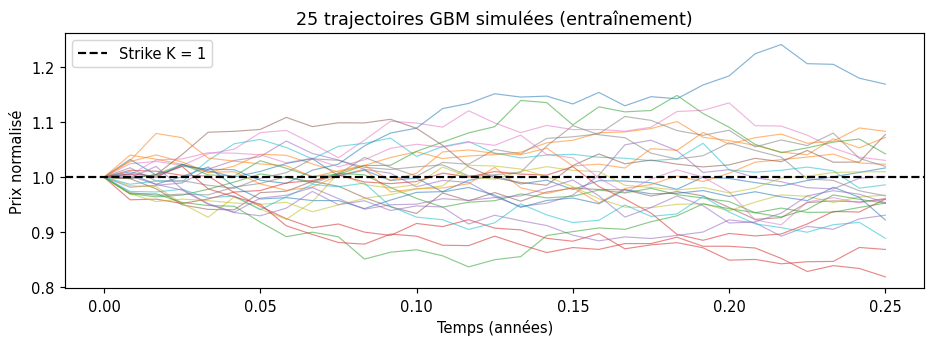

In [4]:
def simulate_gbm(n_paths, n_steps, S0, mu, sigma, T, seed):
    """Trajectoires indépendantes, shape (n_paths, n_steps+1)."""
    if n_paths <= 0 or n_steps <= 0 or T <= 0 or sigma <= 0:
        raise ValueError('Paramètres de simulation invalides')
    rng = np.random.default_rng(seed)
    dt = T / n_steps
    Z = rng.standard_normal((n_paths, n_steps))
    log_returns = (mu - 0.5 * sigma**2) * dt + sigma * np.sqrt(dt) * Z
    log_prices = np.column_stack([np.zeros(n_paths), np.cumsum(log_returns, axis=1)])
    return S0 * np.exp(log_prices)

train_paths = simulate_gbm(N_TRAIN, N_STEPS, S0, MU, SIGMA, T, 42)
valid_paths = simulate_gbm(N_VALID, N_STEPS, S0, MU, SIGMA, T, 2025)
test_paths  = simulate_gbm(N_TEST, N_STEPS, S0, MU, SIGMA, T, 2026)

assert train_paths.shape == (N_TRAIN, N_STEPS + 1)
assert np.all(train_paths > 0) and np.allclose(train_paths[:, 0], S0)

times = np.linspace(0, T, N_STEPS + 1)
plt.figure(figsize=(9, 3.4))
for path in train_paths[:25]:
    plt.plot(times, path, linewidth=0.8, alpha=0.55)
plt.axhline(K, color='black', linestyle='--', label='Strike K = 1')
plt.title('25 trajectoires GBM simulées (entraînement)')
plt.xlabel('Temps (années)'); plt.ylabel('Prix normalisé')
plt.legend(); plt.tight_layout(); plt.show()

## 2 — Stratégie classique et coût de couverture

Pour un call européen sans dividendes, la stratégie de référence est le delta de Black-Scholes :

$$\Delta_t=\Phi(d_1),\qquad d_1=\frac{\log(S_t/K)+(r+\sigma^2/2)(T-t)}{\sigma\sqrt{T-t}}.$$

Une **position** $H_i$ représente la quantité de sous-jacent détenue entre $t_i$ et $t_{i+1}$ pour couvrir **un call vendu**. La valeur finale à financer dépend des achats et ventes successifs, des frais et du règlement de l'option.

Pour éviter la confusion, nous suivons **deux indicateurs distincts** :

- $\operatorname{moyenne}(Z)$ : coût moyen de couverture, qui n'est pas la fonction minimisée par notre réseau ;
- $\operatorname{écart\text{-}type}(Z)$ : dispersion du coût de couverture, **fonction de perte du réseau**.

Les frais proportionnels sont $\alpha |\Delta H_i|S_{t_i}$ aux dates intermédiaires ; au règlement physique final on achète ou revend l'écart entre la position finale et le nombre d'actions dû au détenteur du call. **Conformément au code fourni, l'ouverture initiale est sans commission.**

In [6]:
def bs_call_delta(S, K, tau, r, sigma):
    S = np.asarray(S, dtype=float)
    tau = np.asarray(tau, dtype=float)
    tau_safe = np.maximum(tau, 1e-12)
    d1 = (np.log(S / K) + (r + 0.5 * sigma**2) * tau_safe) / (sigma * np.sqrt(tau_safe))
    return np.where(tau <= 0, np.where(S > K, 1., np.where(S < K, 0., 0.5)), norm.cdf(d1))

def bs_hedging_positions(paths, T, sigma, r=0., K=1.):
    n = paths.shape[1] - 1
    tau = T - np.arange(n) * T / n
    return bs_call_delta(paths[:, :-1], K, tau[None, :], r, sigma)

def hedging_cost(paths, hedges, alpha, T, r=0., K=1.):
    """Coût actualisé par unité de S0, call physiquement livré, sans frais d'entrée.

    paths : (batch, n+1), hedges : (batch, n).
    Les chemins doivent être normalisés par leur valeur initiale ; K=1.
    Le calcul est différentiable en hedges (utile à backpropagation).
    """
    if paths.ndim != 2 or hedges.shape != (len(paths), paths.shape[1] - 1):
        raise ValueError('Dimensions incompatibles entre prix et positions')
    n = hedges.shape[1]
    prices = paths / paths[:, :1]
    dt = T / n
    times = torch.arange(1, n, device=paths.device, dtype=paths.dtype) * dt
    discounts = torch.exp(-r * times)
    changes = hedges[:, 1:] - hedges[:, :-1]
    intermediate = ((changes + alpha * torch.abs(changes)) * prices[:, 1:n] * discounts).sum(dim=1)

    # À maturité : le vendeur doit 1 action si le call est dans la monnaie,
    # et 0 sinon. Pour un call exercé, il encaisse le strike K.
    final_price = prices[:, -1]
    target = (final_price >= K).to(paths.dtype)
    adjustment = target - hedges[:, -1]
    terminal = adjustment * final_price + alpha * torch.abs(adjustment) * final_price - target * K
    return hedges[:, 0] + intermediate + torch.exp(paths.new_tensor(-r * T)) * terminal

def as_tensor(a):
    return torch.as_tensor(a, dtype=torch.float32)

def trading_stats(paths, positions, alpha, T, r=0., K=1., threshold=1e-4):
    """Frais intermédiaires et au règlement (sans frais d'ouverture)."""
    n = positions.shape[1]
    prices = paths / paths[:, :1]
    intermediate_trades = positions[:, 1:] - positions[:, :-1]
    target = (prices[:, -1] >= K).to(paths.dtype)
    final_trade = target - positions[:, -1]
    discounts = torch.exp(-r * torch.arange(1, n, dtype=paths.dtype) * T / n)
    fee_mid = alpha * (intermediate_trades.abs() * prices[:, 1:n] * discounts).sum(dim=1)
    fee_end = alpha * final_trade.abs() * prices[:, -1] * np.exp(-r * T)
    return {
        'Frais moyens (%)': 100 * (fee_mid + fee_end).mean().item(),
        'Rééquilibrages moyens': (intermediate_trades.abs() > threshold).float().sum(dim=1).mean().item(),
        'Volume intermédiaire moyen': intermediate_trades.abs().sum(dim=1).mean().item(),
    }

def evaluate(paths_numpy, positions_tensor, alpha, T, r=0., K=1.):
    paths_tensor = as_tensor(paths_numpy)
    with torch.no_grad():
        costs = hedging_cost(paths_tensor, positions_tensor, alpha, T, r=r, K=K)
        stats = trading_stats(paths_tensor, positions_tensor, alpha, T, r=r, K=K)
        return {
            'Coût moyen (%)': 100 * costs.mean().item(),
            'Écart-type (%)': 100 * costs.std(unbiased=False).item(),
            **stats,
        }

# Vérifications élémentaires, lisibles et indépendantes du réseau.
p = as_tensor([[1., 1., 1.], [1., 1.10, 1.20], [1., 0.90, 0.80]])
h0 = torch.zeros((3, 2))
assert torch.allclose(hedging_cost(p, h0, 0., T=1., r=0.), as_tensor([0., 0.20, 0.]))
# À prix final exactement égal au strike, notre convention considère le call exercé.
assert np.isclose(hedging_cost(p[:1], h0[:1], 0.02, T=1., r=0.).item(), 0.02)
assert np.isclose(float(bs_call_delta(1., 1., 0.25, 0., 0.2)), 0.5199, atol=0.0001)
print('Tests élémentaires : OK')
# Contrôle complémentaire : deux transactions non nulles, calculées à la main.
p_check = as_tensor([[1., 1.10, 1.20]])
h_check = as_tensor([[0.25, 0.50]])
manual_cost = 0.25 + (0.25 + 0.01 * 0.25) * 1.10 + (0.50 + 0.01 * 0.50) * 1.20 - 1.0
assert np.isclose(hedging_cost(p_check, h_check, .01, T=1.).item(), manual_cost, atol=1e-6)
print('Contrôle comptable indépendant : OK (achats intermédiaires et règlement final).')


Tests élémentaires : OK
Contrôle comptable indépendant : OK (achats intermédiaires et règlement final).


## 3 — Réseau dense et fonction de perte

Le réseau reçoit à chaque date trois informations connues : le prix normalisé $S_t/K$, le **temps restant** $T-t$ et la dernière quantité détenue $H_{t-1}$. Il choisit la nouvelle quantité $H_t$.

La même fonction (réseau dense **3 → 64 → 32 → 1**, activations ReLU) est réutilisée aux 30 dates. Ce n'est **pas** un RNN : la position passée est simplement une entrée du réseau. La sortie n'est pas directement comparée à un « vrai delta » : on optimise le **résultat de toute la couverture**.

$$\mathcal L(\theta)=\sqrt{\frac{1}{N}\sum_{i=1}^N\big(Z_i(\theta)-\overline Z(\theta)\big)^2}.$$

Ici $Z_i(\theta)$ est le coût final de couverture sur la trajectoire $i$. L'objectif minimise sa **dispersion** (risque de couverture), **pas son espérance**. Le réseau est entraîné avec Adam en mini-batch ; les gradients sont calculés à travers les positions de couverture successives (`loss.backward()`).

**Protocole :** 256 trajectoires simulées en entraînement, 256 en validation et 1 024 en test. Les graines sont fixées. La meilleure époque est choisie **exclusivement sur la validation** ; le test est utilisé après ce choix.

In [8]:
class DeltaNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(3, 64), nn.ReLU(),
            nn.Linear(64, 32), nn.ReLU(),
            nn.Linear(32, 1)
        )

    def forward(self, features):
        return self.network(features).squeeze(-1)

def neural_hedging_positions(model, paths, T, K=1.):
    n_steps = paths.shape[1] - 1
    previous_hedge = torch.zeros(len(paths), dtype=paths.dtype, device=paths.device)
    positions = []
    for i in range(n_steps):
        features = torch.stack([
            paths[:, i] / K,
            torch.full_like(previous_hedge, T * (1 - i / n_steps)),
            previous_hedge
        ], dim=1)
        current_hedge = model(features)
        positions.append(current_hedge)
        previous_hedge = current_hedge
    return torch.stack(positions, dim=1)

def train_model(train_paths, valid_paths, alpha, T, seed=42,
                epochs=160, batch_size=64, lr=1e-3):
    torch.manual_seed(seed)
    model = DeltaNN()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    train_tensor, valid_tensor = as_tensor(train_paths), as_tensor(valid_paths)
    history = []
    best_val, best_epoch, best_weights = float('inf'), 0, None
    for epoch in range(1, epochs + 1):
        model.train()
        for ids in torch.randperm(len(train_tensor)).split(batch_size):
            batch = train_tensor[ids]
            positions = neural_hedging_positions(model, batch, T)
            costs = hedging_cost(batch, positions, alpha, T)
            loss = costs.std(unbiased=False)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        model.eval()
        with torch.no_grad():
            train_costs = hedging_cost(train_tensor,
                neural_hedging_positions(model, train_tensor, T), alpha, T)
            valid_costs = hedging_cost(valid_tensor,
                neural_hedging_positions(model, valid_tensor, T), alpha, T)
            train_std = train_costs.std(unbiased=False).item()
            valid_std = valid_costs.std(unbiased=False).item()
        history.append((epoch, train_std, valid_std))
        if valid_std < best_val:
            best_val = valid_std
            best_epoch = epoch
            best_weights = copy.deepcopy(model.state_dict())
    model.load_state_dict(best_weights)
    return model, pd.DataFrame(history, columns=['Époque', 'Train', 'Validation']), best_epoch

print('Réseau :', sum(p.numel() for p in DeltaNN().parameters()), 'paramètres')

Réseau : 2369 paramètres


Meilleure époque choisie sur validation : 600
Validation : 0.850 % (min), 0.863 % (dernière).
Attention : meilleure époque proche de la fin ; la convergence n’est pas démontrée.
       Stratégie  ...  Volume intermédiaire moyen
0  Black-Scholes  ...                       1.718
1   Deep Hedging  ...                       1.161

[2 rows x 6 columns]


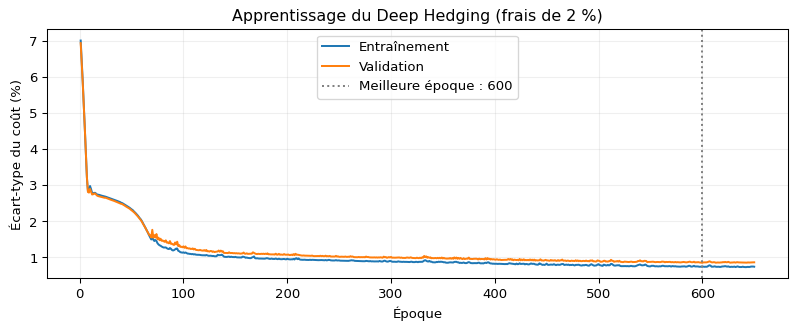

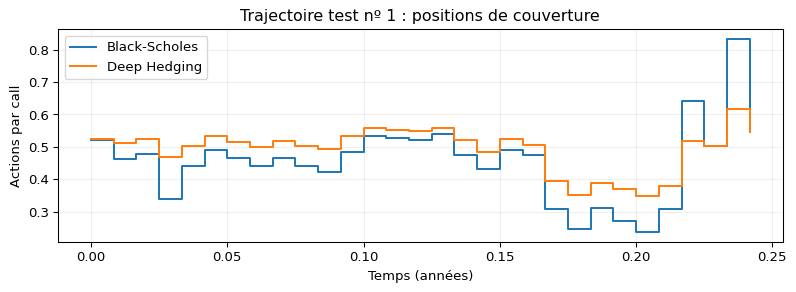

In [9]:
ALPHA_REF = 0.02
model_ref, history_ref, epoch_ref = train_model(train_paths, valid_paths,
    alpha=ALPHA_REF, T=T, epochs=N_EPOCHS, batch_size=BATCH_SIZE, lr=LR)

fig, ax = plt.subplots(figsize=(8.5, 3.6))
ax.plot(history_ref['Époque'], 100 * history_ref['Train'], label='Entraînement')
ax.plot(history_ref['Époque'], 100 * history_ref['Validation'], label='Validation')
ax.axvline(epoch_ref, color='grey', linestyle=':', label=f'Meilleure époque : {epoch_ref}')
ax.set(xlabel='Époque', ylabel='Écart-type du coût (%)', title='Apprentissage du Deep Hedging (frais de 2 %)')
ax.legend(); ax.grid(alpha=0.2); plt.tight_layout(); plt.show()
print('Meilleure époque choisie sur validation :', epoch_ref)
print(f"Validation : {100 * history_ref['Validation'].min():.3f} % (min), " 
      f"{100 * history_ref['Validation'].iloc[-1]:.3f} % (dernière).")
# Diagnostic : une meilleure époque en toute fin de budget demande de la prudence.
if epoch_ref >= 0.90 * N_EPOCHS:
    print('Attention : meilleure époque proche de la fin ; la convergence n’est pas démontrée.')
else:
    print('Meilleure époque avant la fin ; regarder la stabilité de la courbe.')

bs_ref = as_tensor(bs_hedging_positions(test_paths, T, SIGMA))
with torch.no_grad():
    nn_ref = neural_hedging_positions(model_ref, as_tensor(test_paths), T)
first_table = pd.DataFrame([
    {'Stratégie': 'Black-Scholes', **evaluate(test_paths, bs_ref, ALPHA_REF, T)},
    {'Stratégie': 'Deep Hedging', **evaluate(test_paths, nn_ref, ALPHA_REF, T)}
])
display(first_table.round(3))
first_table.to_csv(OUTPUT_DIR / '01_comparaison_reference.csv', index=False)

fig, ax = plt.subplots(figsize=(8.5, 3.2))
ax.step(times[:-1], bs_ref[0].numpy(), where='post', label='Black-Scholes')
ax.step(times[:-1], nn_ref[0].detach().numpy(), where='post', label='Deep Hedging')
ax.set(xlabel='Temps (années)', ylabel='Actions par call', title='Trajectoire test nº 1 : positions de couverture')
ax.legend(); ax.grid(alpha=0.2); plt.tight_layout(); plt.show()

In [10]:
# Lecture du premier résultat : valeurs calculées, sans conclusion prédéfinie.
b0 = first_table.set_index('Stratégie').loc['Black-Scholes']
n0 = first_table.set_index('Stratégie').loc['Deep Hedging']
reduc_std = 100 * (1 - n0['Écart-type (%)'] / b0['Écart-type (%)'])
reduc_frais = 100 * (1 - n0['Frais moyens (%)'] / b0['Frais moyens (%)'])
print(f"Sur le test indépendant, avec 2 % de frais :")
print(f"- Écart-type : {b0['Écart-type (%)']:.3f} % (BS) contre {n0['Écart-type (%)']:.3f} % (NN) "
      f"; différence relative : {reduc_std:+.1f} % de réduction.")
print(f"- Frais : {b0['Frais moyens (%)']:.3f} % (BS) contre {n0['Frais moyens (%)']:.3f} % (NN) "
      f"; réduction relative : {reduc_frais:.1f} %.")
print(f"- Coût moyen : {b0['Coût moyen (%)']:.3f} % (BS) contre {n0['Coût moyen (%)']:.3f} % (NN).")
print('Ces résultats concernent cette simulation et ces paramètres, pas une domination générale du réseau.')

Sur le test indépendant, avec 2 % de frais :
- Écart-type : 1.662 % (BS) contre 0.833 % (NN) ; différence relative : +49.9 % de réduction.
- Frais : 3.611 % (BS) contre 2.675 % (NN) ; réduction relative : 25.9 %.
- Coût moyen : 7.626 % (BS) contre 6.680 % (NN).
Ces résultats concernent cette simulation et ces paramètres, pas une domination générale du réseau.


### Petite expérience de cours : taille du dataset

Nous comparons **128, 256 et 512 trajectoires** avec la même architecture, la même validation et le même test. Pour limiter les temps de calcul, les trois essais utilisent **250 époques**, un budget plus court que l'expérience principale (650). Les trois configurations sont donc comparables **entre elles**, mais leurs résultats ne remplacent pas la stratégie principale entraînée plus longtemps. Une seule graine par taille : la conclusion reste exploratoire.

   Trajectoires train  ...  Volume intermédiaire moyen
0                 128  ...                       0.848
1                 256  ...                       0.991
2                 512  ...                       1.066

[3 rows x 7 columns]


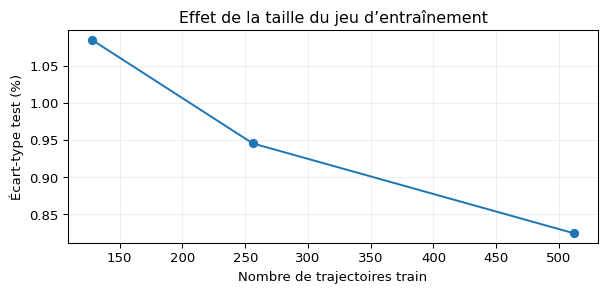

In [12]:
size_rows = []
for n in [128, 256, 512]:
    new_train = simulate_gbm(n, N_STEPS, S0, MU, SIGMA, T, seed=42)
    m, _, best_e = train_model(new_train, valid_paths, ALPHA_REF, T,
                               seed=SEED, epochs=250, batch_size=BATCH_SIZE, lr=LR)
    with torch.no_grad():
        pos = neural_hedging_positions(m, as_tensor(test_paths), T)
    size_rows.append({'Trajectoires train': n, 'Époque retenue': best_e,
                      **evaluate(test_paths, pos, ALPHA_REF, T)})
size_table = pd.DataFrame(size_rows)
display(size_table.round(3))
size_table.to_csv(OUTPUT_DIR / '01_tailles_donnees.csv', index=False)

plt.figure(figsize=(6.5, 3.2))
plt.plot(size_table['Trajectoires train'], size_table['Écart-type (%)'], marker='o')
plt.xlabel('Nombre de trajectoires train'); plt.ylabel('Écart-type test (%)')
plt.title('Effet de la taille du jeu d’entraînement')
plt.grid(alpha=0.2); plt.tight_layout(); plt.show()

In [13]:
sizes_sorted = size_table.sort_values('Trajectoires train')
print('Écart-type de test (%) selon le nombre de trajectoires :')
for _, row in sizes_sorted.iterrows():
    print(f"  {int(row['Trajectoires train']):3d} trajectoires : {row['Écart-type (%)']:.3f} % (époque {int(row['Époque retenue'])}).")
print('Ces valeurs décrivent une expérience contrôlée, pas une loi générale du nombre de données.')

Écart-type de test (%) selon le nombre de trajectoires :
  128 trajectoires : 1.085 % (époque 248).
  256 trajectoires : 0.946 % (époque 250).
  512 trajectoires : 0.825 % (époque 242).
Ces valeurs décrivent une expérience contrôlée, pas une loi générale du nombre de données.


## 4 — Effet des coûts de transaction (étudiant 2)

**Question :** *le réseau adapte-t-il la couverture quand les transactions deviennent plus coûteuses ?*

Nous entraînons **un réseau distinct** pour chaque taux $\alpha\in\{0\%,\ 0{,}5\%,\ 2\%\}$. Les trois stratégies neuronales sont évaluées sur les **mêmes 1 024 trajectoires** que Black-Scholes. On étudie le coût moyen, son écart-type et les frais payés. Nous regarderons aussi le volume échangé : de petits ajustements répétés peuvent être peu chers en montant, même s'ils restent nombreux.

Il s'agit de **frais proportionnels à la quantité échangée** ; ce protocole n'est pas un simulateur complet d'un courtier.

   Frais (%)      Stratégie  ...  Rééquilibrages moyens  Volume intermédiaire moyen
0        0.0  Black-Scholes  ...                 27.973                       1.718
1        0.0   Deep Hedging  ...                 28.958                       1.678
2        0.5  Black-Scholes  ...                 27.973                       1.718
3        0.5   Deep Hedging  ...                 28.961                       1.466
4        2.0  Black-Scholes  ...                 27.973                       1.718
5        2.0   Deep Hedging  ...                 28.947                       1.161

[6 rows x 7 columns]


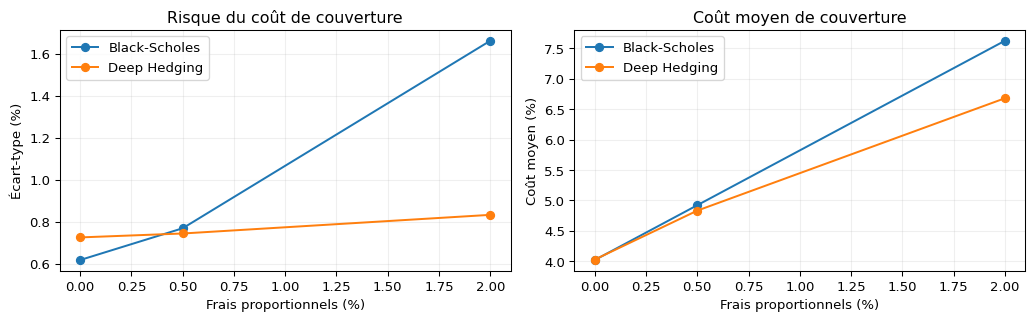

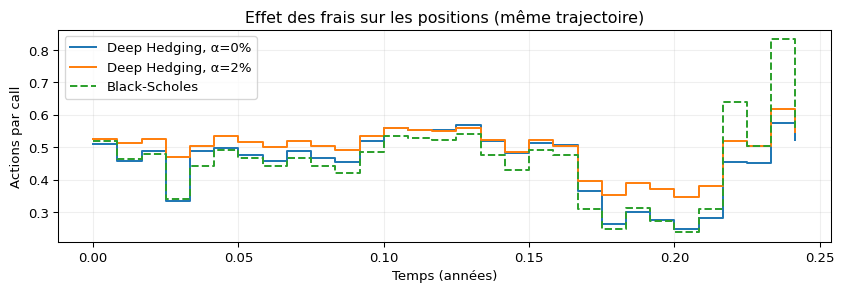

In [15]:
alphas = [0., 0.005, 0.02]
models_by_alpha = {ALPHA_REF: model_ref}
fee_rows = []
positions_by_alpha = {}
for alpha in alphas:
    if alpha not in models_by_alpha:
        models_by_alpha[alpha], _, _ = train_model(train_paths, valid_paths,
            alpha=alpha, T=T, seed=SEED, epochs=N_EPOCHS, batch_size=BATCH_SIZE, lr=LR)
    with torch.no_grad():
        pos_nn = neural_hedging_positions(models_by_alpha[alpha], as_tensor(test_paths), T)
    positions_by_alpha[alpha] = pos_nn
    pos_bs = as_tensor(bs_hedging_positions(test_paths, T, SIGMA))
    fee_rows.extend([
        {'Frais (%)': alpha * 100, 'Stratégie': 'Black-Scholes', **evaluate(test_paths, pos_bs, alpha, T)},
        {'Frais (%)': alpha * 100, 'Stratégie': 'Deep Hedging', **evaluate(test_paths, pos_nn, alpha, T)},
    ])
fee_table = pd.DataFrame(fee_rows)
display(fee_table.round(3))
fee_table.to_csv(OUTPUT_DIR / '02_sensibilite_frais.csv', index=False)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for name, group in fee_table.groupby('Stratégie'):
    axes[0].plot(group['Frais (%)'], group['Écart-type (%)'], marker='o', label=name)
    axes[1].plot(group['Frais (%)'], group['Coût moyen (%)'], marker='o', label=name)
axes[0].set(title='Risque du coût de couverture', ylabel='Écart-type (%)')
axes[1].set(title='Coût moyen de couverture', ylabel='Coût moyen (%)')
for ax in axes:
    ax.set_xlabel('Frais proportionnels (%)'); ax.grid(alpha=0.2); ax.legend()
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(9, 3.2))
for a in [0., 0.02]:
    ax.step(times[:-1], positions_by_alpha[a][0].detach().numpy(),
            where='post', label=f'Deep Hedging, α={a:.0%}')
ax.step(times[:-1], pos_bs[0].numpy(), where='post', linestyle='--', label='Black-Scholes')
ax.set(xlabel='Temps (années)', ylabel='Actions par call', title='Effet des frais sur les positions (même trajectoire)')
ax.legend(); ax.grid(alpha=0.2); plt.tight_layout(); plt.show()

In [16]:
# Interprétation calculée du tableau, sur le test indépendant.
for alpha, group in fee_table.groupby('Frais (%)', sort=True):
    g = group.set_index('Stratégie')
    b, n = g.loc['Black-Scholes'], g.loc['Deep Hedging']
    print(f"\nFrais {alpha:g} % :")
    print(f"  Écart-type BS / NN : {b['Écart-type (%)']:.3f} % / {n['Écart-type (%)']:.3f} %")
    print(f"  Coût moyen BS / NN : {b['Coût moyen (%)']:.3f} % / {n['Coût moyen (%)']:.3f} %")
    print(f"  Volume échangé BS / NN : {b['Volume intermédiaire moyen']:.3f} / {n['Volume intermédiaire moyen']:.3f}")
    print(f"  Rééquilibrages BS / NN : {b['Rééquilibrages moyens']:.1f} / {n['Rééquilibrages moyens']:.1f}")
print('\nAttention : moins de volume n’implique pas nécessairement moins d’ordres. ' 
      'Les performances reposent sur une fonction de perte en écart-type, pas sur la réduction automatique du coût moyen.')


Frais 0 % :
  Écart-type BS / NN : 0.618 % / 0.725 %
  Coût moyen BS / NN : 4.016 % / 4.023 %
  Volume échangé BS / NN : 1.718 / 1.678
  Rééquilibrages BS / NN : 28.0 / 29.0

Frais 0.5 % :
  Écart-type BS / NN : 0.769 % / 0.744 %
  Coût moyen BS / NN : 4.918 % / 4.829 %
  Volume échangé BS / NN : 1.718 / 1.466
  Rééquilibrages BS / NN : 28.0 / 29.0

Frais 2 % :
  Écart-type BS / NN : 1.662 % / 0.833 %
  Coût moyen BS / NN : 7.626 % / 6.680 %
  Volume échangé BS / NN : 1.718 / 1.161
  Rééquilibrages BS / NN : 28.0 / 28.9

Attention : moins de volume n’implique pas nécessairement moins d’ordres. Les performances reposent sur une fonction de perte en écart-type, pas sur la réduction automatique du coût moyen.


### Exemple concret : combien représentent les frais proportionnels en euros ?

Pour **un call hypothétique de notionnel initial 1 000 € ou 10 000 €**, les frais moyens du tableau précédent se multiplient simplement par le notionnel. On conserve les conventions du calcul (sans frais d'ouverture) : **ceci n'est pas une simulation des tarifs fixes de Trade Republic**.

Ce calcul est plus informatif qu'un forfait de 1 € par ordre dans notre cas : les deux stratégies effectuent presque autant d'ajustements, mais pas sur les **mêmes volumes**.

In [18]:
euros_rows = []
for alpha in [0.005, 0.02]:
    group = fee_table.loc[np.isclose(fee_table['Frais (%)'], 100 * alpha)].set_index('Stratégie')
    for notional in [1000, 10000]:
        bs_fee = float(group.loc['Black-Scholes', 'Frais moyens (%)'] * notional / 100)
        nn_fee = float(group.loc['Deep Hedging', 'Frais moyens (%)'] * notional / 100)
        euros_rows.append({'Frais (%)': alpha * 100, 'Notionnel initial (€)': notional,
                          'Frais moyens BS (€)': bs_fee,
                          'Frais moyens NN (€)': nn_fee,
                          'Différence BS − NN (€)': bs_fee - nn_fee})
euros_table = pd.DataFrame(euros_rows)
display(euros_table.round(2))
euros_table.to_csv(OUTPUT_DIR / '02_frais_en_euros.csv', index=False)
print('Ces montants illustrent le coût des transactions proportionnelles, pas le profit net du portefeuille.')

   Frais (%)  ...  Différence BS − NN (€)
0        0.5  ...                    0.95
1        0.5  ...                    9.46
2        2.0  ...                    9.35
3        2.0  ...                   93.52

[4 rows x 5 columns]
Ces montants illustrent le coût des transactions proportionnelles, pas le profit net du portefeuille.


## 5 — Prix historiques observés (étudiant 3)

**But :** appliquer les stratégies à des trajectoires réelles de prix. Les données de test ne servent pas à entraîner le réseau, qui est appris sur des **GBM simulés**. Nous ne prétendons pas reproduire des transactions historiques effectivement exécutées.

**Deux sources possibles :**

- `SOURCE = 'demo'` : échantillon **réel** de cours relatifs hebdomadaires AAPL issu de `plotly.express.data.stocks()`, 2018–2019, fourni avec le projet. **Il ne vient pas de Yahoo Finance** et sa taille est limitée : il sert à vérifier toutes les cellules sans Internet.
- `SOURCE = 'yahoo_csv'` : fichier `historique_yahoo.csv` issu de Yahoo Finance (via le script `telecharger_yahoo.py` fourni). Pour la remise, privilégier cette option, avec les cours quotidiens ajustés de **SPY**, ETF coté, sur 2021 et 2022.

Sur chaque fenêtre, on construit **un nouveau call européen fictif ATM** ($S_0=K=1$). Les dates des couvertures et la maturité sont cohérentes : **12 semaines** en démonstration ($T=12/52$) et **30 séances** dans l'étude Yahoo ($T=30/252$). Le réseau est réentraîné sur des simulations pour l'horizon choisi.

Pour Yahoo, nous prendrons des fenêtres **non chevauchantes** (pas de 30 séances) pour une lecture plus défendable ; le nombre de fenêtres restera limité. En démonstration, les fenêtres hebdomadaires se chevauchent : les statistiques restent descriptives seulement. Pour Black-Scholes, $\sigma=20\%$ reste une hypothèse fixée *a priori* : nous ne calibrons pas la volatilité sur le futur des données.

Source : Plotly, échantillon 2018–2019 (PAS Yahoo) | hebdomadaire | 105 observations
        Date     Close
0 2018-01-01  1.000000
1 2018-01-08  1.011943
2 2018-01-15  1.019771


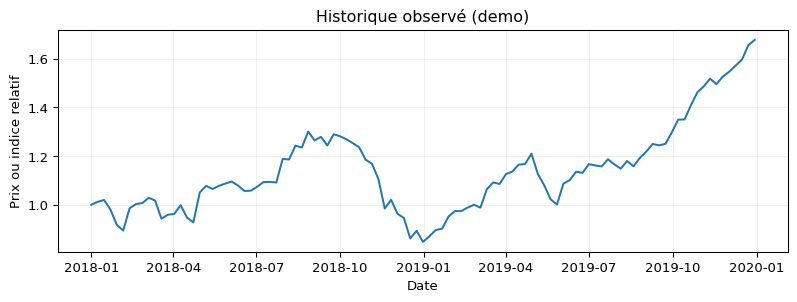

In [20]:
SOURCE = 'demo'           # Pour la remise finale : 'yahoo_csv' (voir README)
YAHOO_CSV = Path('historique_yahoo.csv')
DEMO_CSV = Path('donnees_demo_plotly_AAPL_2018_2019.csv')

# Le CSV du dossier joint est le premier choix ; sur l'environnement de génération,
# le chemin /mnt/data est également possible.
def find_data_file(p):
    if p.exists():
        return p
    mounted = Path('/mnt/data') / p.name
    if mounted.exists():
        return mounted
    raise FileNotFoundError(f'Fichier absent : {p}. Décompresser le paquet à côté du notebook.')

source_file = find_data_file(DEMO_CSV if SOURCE == 'demo' else YAHOO_CSV)
raw = pd.read_csv(source_file)
raw.columns = [str(c).strip() for c in raw.columns]
if 'Date' not in raw.columns:
    raise ValueError('Le fichier doit contenir la colonne Date.')
price_col = 'Adj Close' if 'Adj Close' in raw.columns else 'Close'
if price_col not in raw.columns:
    raise ValueError('Colonne de prix attendue : Adj Close ou Close')
raw['Date'] = pd.to_datetime(raw['Date'], errors='coerce')
raw[price_col] = pd.to_numeric(raw[price_col], errors='coerce')
raw = raw[['Date', price_col]].dropna().sort_values('Date').drop_duplicates('Date')
raw = raw.loc[raw[price_col] > 0].reset_index(drop=True)
if SOURCE == 'demo':
    N_HIST, T_HIST, years, PERIOD = 12, 12 / 52, [2018, 2019], 'hebdomadaire'
else:
    N_HIST, T_HIST, years, PERIOD = 30, 30 / 252, [2021, 2022], 'quotidien'

if any((raw['Date'].dt.year == yr).sum() < N_HIST + 1 for yr in years):
    raise ValueError(f'Il faut au moins {N_HIST+1} observations par année parmi {years}. '
                     f'Adapter les années ou fournir un historique plus long.')
print('Source :', 'Plotly, échantillon 2018–2019 (PAS Yahoo)' if SOURCE == 'demo' else 'CSV Yahoo fourni',
      '|', PERIOD, '|', len(raw), 'observations')
display(raw.head(3))

fig, ax = plt.subplots(figsize=(8.5, 3.3))
ax.plot(raw['Date'], raw[price_col]); ax.set(title=f'Historique observé ({SOURCE})', ylabel='Prix ou indice relatif', xlabel='Date')
ax.grid(alpha=0.2); plt.tight_layout(); plt.show()

In [21]:
def historical_windows(frame, column, year, n_steps, stride):
    """Fenêtres historiques, normalisées à 1 et strictement contenues dans l'année."""
    part = frame.loc[frame['Date'].dt.year == year].reset_index(drop=True)
    windows, labels = [], []
    for start in range(0, len(part) - n_steps, stride):
        raw_path = part[column].iloc[start:start + n_steps + 1].to_numpy(float)
        path = raw_path / raw_path[0]
        if np.all(np.isfinite(path)) and np.all(path > 0):
            windows.append(path)
            labels.append((part['Date'].iloc[start], part['Date'].iloc[start + n_steps]))
    if not windows:
        raise ValueError('Aucune fenêtre historique trouvée pour ' + str(year))
    return np.stack(windows), labels

stride = 4 if SOURCE == 'demo' else 30  # Yahoo : fenêtres non chevauchantes ; démo : chevauchement signalé
hist_groups = {}
for y in years:
    hist_groups[y], _ = historical_windows(raw, price_col, y, N_HIST, stride)
    print(y, ':', len(hist_groups[y]), 'fenêtres de', N_HIST + 1, 'points')

# Pour chaque fréquence, nous entraînons uniquement sur des données SIMULÉES.
# Aucune fenêtre historique n'entre dans les jeux train/validation.
hist_train = simulate_gbm(256, N_HIST, 1., MU, SIGMA, T_HIST, seed=804)
hist_valid = simulate_gbm(256, N_HIST, 1., MU, SIGMA, T_HIST, seed=805)
ALPHA_HIST = 0.005
hist_model, hist_history, hist_epoch = train_model(hist_train, hist_valid, ALPHA_HIST,
                                                  T_HIST, seed=SEED, epochs=N_EPOCHS)
print('Réseau réentraîné pour la fréquence historique ; époque retenue :', hist_epoch)

2018 : 11 fenêtres de 13 points
2019 : 10 fenêtres de 13 points
Réseau réentraîné pour la fréquence historique ; époque retenue : 538


   Période      Stratégie  ...  Rééquilibrages moyens  Volume intermédiaire moyen
0     2018  Black-Scholes  ...                 10.364                       1.057
1     2018   Deep Hedging  ...                 10.909                       1.014
2     2019  Black-Scholes  ...                 10.200                       0.780
3     2019   Deep Hedging  ...                 11.000                       0.775

[4 rows x 8 columns]


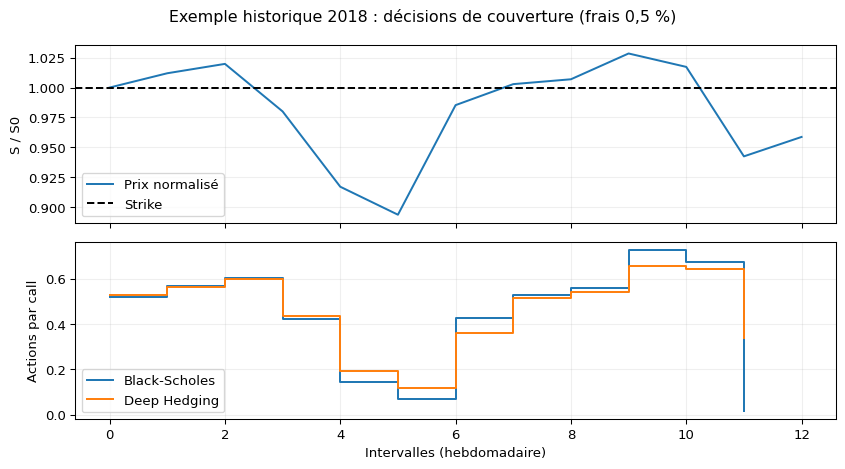

In [22]:
hist_rows = []
for y, windows in hist_groups.items():
    bs_pos = as_tensor(bs_hedging_positions(windows, T_HIST, SIGMA))
    with torch.no_grad():
        deep_pos = neural_hedging_positions(hist_model, as_tensor(windows), T_HIST)
    for name, pos in [('Black-Scholes', bs_pos), ('Deep Hedging', deep_pos)]:
        hist_rows.append({'Période': y, 'Stratégie': name, 'Fenêtres': len(windows),
                         **evaluate(windows, pos, ALPHA_HIST, T_HIST)})
hist_table = pd.DataFrame(hist_rows)
display(hist_table.round(3))
hist_table.to_csv(OUTPUT_DIR / '03_comparaison_historique.csv', index=False)

# Une fenêtre illustrative de la première période.
example_year = years[0]
example_hist = hist_groups[example_year][:1]
bs_example = bs_hedging_positions(example_hist, T_HIST, SIGMA)[0]
with torch.no_grad():
    nn_example = neural_hedging_positions(hist_model, as_tensor(example_hist), T_HIST)[0].numpy()

fig, axes = plt.subplots(2, 1, figsize=(9, 5), sharex=True)
axes[0].plot(example_hist[0], label='Prix normalisé')
axes[0].axhline(1, color='black', ls='--', label='Strike')
axes[0].set_ylabel('S / S0'); axes[0].legend(); axes[0].grid(alpha=0.2)
axes[1].step(np.arange(N_HIST), bs_example, where='post', label='Black-Scholes')
axes[1].step(np.arange(N_HIST), nn_example, where='post', label='Deep Hedging')
axes[1].set(xlabel=f'Intervalles ({PERIOD})', ylabel='Actions par call')
axes[1].legend(); axes[1].grid(alpha=0.2)
fig.suptitle(f'Exemple historique {example_year} : décisions de couverture (frais 0,5 %)')
plt.tight_layout(); plt.show()

In [23]:
# Lecture critique des résultats historiques, sans affirmer une supériorité générale.
for year, group in hist_table.groupby('Période'):
    g = group.set_index('Stratégie')
    b, n = g.loc['Black-Scholes'], g.loc['Deep Hedging']
    winner = 'Deep Hedging' if n['Écart-type (%)'] < b['Écart-type (%)'] else 'Black-Scholes'
    print(f"{year} — {int(b['Fenêtres'])} fenêtres : écart-type BS {b['Écart-type (%)']:.3f} % / "
          f"NN {n['Écart-type (%)']:.3f} % ; meilleur sur CE critère : {winner}.")
    print(f"    Coût moyen BS {b['Coût moyen (%)']:.3f} % / NN {n['Coût moyen (%)']:.3f} %. ")
print('Ces statistiques sont descriptives : petit échantillon historique' +
      (' avec fenêtres chevauchantes.' if SOURCE == 'demo' else ' avec fenêtres non chevauchantes.'))
print('Le réseau reste calibré sur un GBM à volatilité fixée à 20 % : ce n’est pas un backtest de produits cotés.')

2018 — 11 fenêtres : écart-type BS 1.864 % / NN 1.373 % ; meilleur sur CE critère : Deep Hedging.
    Coût moyen BS 6.218 % / NN 6.305 %. 
2019 — 10 fenêtres : écart-type BS 0.592 % / NN 0.756 % ; meilleur sur CE critère : Black-Scholes.
    Coût moyen BS 4.562 % / NN 4.619 %. 
Ces statistiques sont descriptives : petit échantillon historique avec fenêtres chevauchantes.
Le réseau reste calibré sur un GBM à volatilité fixée à 20 % : ce n’est pas un backtest de produits cotés.


## 6 — Bilan et limites

**Ce que nous apprenons :** nous avons reproduit une comparaison de couverture entre un delta analytique de Black-Scholes et un réseau dense dont les positions sont apprises en minimisant la dispersion du coût final. La méthodologie permet de regarder **sur des trajectoires de test** l'effet des frais, l'intensité des transactions et les différences entre prix simulés et observés. Les conclusions quantitatives sont affichées **directement après les tableaux**, afin qu'elles restent exactes lorsque l'on change les données et réexécute le notebook.

**Ce que nous ne démontrons pas :** que le Deep Hedging est toujours supérieur à Black-Scholes, que le réseau minimise le coût moyen, ou que les coûts et transactions simulés correspondent à des exécutions réellement possibles chez un courtier. En particulier :

1. La dynamique GBM est une simplification ; l'écart entre la volatilité imposée et celle du marché peut affecter Black-Scholes et le réseau.
2. L'objectif minimise un **écart-type** de coûts, pas directement la valeur attendue de ces coûts. Le coût moyen doit toujours être lu séparément.
3. Les frais initiaux ne sont pas facturés, les coûts de spread, les restrictions de position, la liquidité et les conditions concrètes de négociation des options sont absents.
4. **Sans CSV Yahoo**, la dernière partie utilise uniquement la démo AAPL de Plotly, avec un échantillon restreint. **Pour la remise, il faut fournir un historique Yahoo, réexécuter le notebook et vérifier les conclusions.**
5. Nous n'avons pas implémenté la stratégie de Leland : il s'agit d'une reproduction **partielle** de l'article.

**Conclusion générale :** l'intérêt de l'exercice est de comprendre le **compromis entre coût des transactions et risque de couverture** et de montrer pourquoi un réseau dense peut apprendre une politique de couverture différente du delta classique. La pertinence d'une méthode dépend du modèle, du niveau de frais et des données testées ; elle ne peut pas être déduite d'une seule trajectoire.

### Références

- Brugière, P., & Turinici, G. (2025), *Model-Free Deep Hedging with Transaction Costs and Light Data Requirements* (article de référence).
- Supports de cours et notebooks de TP du M2 ISF : réseaux denses, descente de gradient, validation, biais-variance.
- Données de secours : `plotly.express.data.stocks()` (AAPL, cours relatifs hebdomadaires 2018–2019).
- Pour la remise : Yahoo Finance via `yfinance`, ETF SPY (source, ticker et dates à documenter dans le notebook).